# 特徴量の選定

## 目的

`customer_features` の特徴量のうち、K-means に入力する特徴量を選ぶ。
対象は区分①〜③ (区分④は解釈用のため対象外)。定義は `docs/customer_features.md` を参照。

## 判断の観点

1. NULL の割合: 利用できる顧客が十分にいるか
2. 分布: ほとんどの顧客が同じ値になっていないか、偏りや外れ値の大きさ
3. 特徴量どうしの関係: 似た情報を持つ組がないか (偏りが大きいため、順位相関で見る)
4. 比較候補の決着: `avg_delivery_delay_days` と `late_delivery_ratio`
5. 意味: 顧客の行動を表しているか、注文の条件の影響が強いか

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from google.cloud import bigquery
from matplotlib.colors import LinearSegmentedColormap

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)

client = bigquery.Client()  # プロジェクトは gcloud の設定から取得する
features = client.query("select * from olist_mart.customer_features").to_dataframe()

# NUMERIC 列は Decimal として読まれるため、分析用に float にする
for col in features.columns:
    if features[col].dtype == "object" and col not in ("customer_unique_id", "top_category", "main_payment_type", "customer_state"):
        features[col] = pd.to_numeric(features[col])

features.shape

/home/seven/workspace/olist-data-platform/.venv/lib/python3.12/site-packages/google/cloud/bigquery/table.py:2128: UserWarning: BigQuery Storage module not found, fetch data with the REST endpoint instead.
  warnings.warn(


(93358, 22)

In [2]:
# 選定の対象 (区分①〜③) と区分
CANDIDATES = {
    "total_items_amount": "①",
    "order_count": "①",
    "days_since_last_purchase": "①",
    "avg_order_items_amount": "③",
    "avg_item_price": "②",
    "freight_ratio": "③",
    "days_since_first_purchase": "③",
    "item_count": "②",
    "distinct_category_count": "③",
    "credit_card_order_ratio": "②",
    "avg_card_installments": "③",
    "has_used_voucher": "③",
    "avg_review_score": "②",
    "has_review_comment": "③",
    "avg_delivery_days": "③",
    "avg_delivery_delay_days": "③",
    "late_delivery_ratio": "③",
}

# 真偽値は 0 / 1 として扱う (NULL は NULL のまま)
X = features[list(CANDIDATES)].copy()
for col in ("has_used_voucher", "has_review_comment"):
    X[col] = X[col].astype("float")
X = X.astype("float")
X.dtypes.value_counts()

float64    17
Name: count, dtype: int64

## 1. NULL の割合と、値のばらつき

- `null_rate`: NULL の割合
- `n_unique`: 値の種類の数
- `top_value_share`: 最も多い値が占める割合 (1 に近いほど、ほとんどの顧客が同じ値)
- `skew`: 歪度 (0 から離れるほど偏りが大きい)

In [3]:
profile = pd.DataFrame({
    "tier": pd.Series(CANDIDATES),
    "null_rate": X.isna().mean(),
    "n_unique": X.nunique(),
    "top_value": X.mode().iloc[0],
    "top_value_share": X.apply(lambda s: s.value_counts(normalize=True).iloc[0]),
    "skew": X.skew(),
    "p01": X.quantile(0.01),
    "median": X.median(),
    "p99": X.quantile(0.99),
    "max": X.max(),
}).round(3)
profile

,tier,null_rate,n_unique,top_value,top_value_share,skew,p01,median,p99,max
total_items_amount,①,0.000,8143,59.9,0.017,9.747,12.000,89.730,1004.990,13440.000
order_count,①,0.000,9,1.0,0.970,11.095,1.000,1.000,2.000,15.000
days_since_last_purchase,①,0.000,611,278.0,0.012,0.447,9.000,218.000,575.000,713.000
avg_order_items_amount,③,0.000,8502,59.9,0.017,9.931,12.000,86.990,997.886,13440.000
avg_item_price,②,0.000,7823,59.9,0.020,7.829,11.490,79.000,899.990,6735.000
freight_ratio,③,0.000,43851,0.0,0.004,1.066,0.024,0.183,0.590,0.955
days_since_first_purchase,③,0.000,612,278.0,0.012,0.430,9.000,221.000,575.000,713.000
item_count,②,0.000,19,1.0,0.876,7.443,1.000,1.000,4.000,24.000
distinct_category_count,③,0.013,5,1.0,0.977,7.645,1.000,1.000,2.000,5.000
credit_card_order_ratio,②,0.000,12,1.0,0.769,-1.284,0.000,1.000,1.000,1.000


## 2. 分布

偏りの大きい特徴量は、対数を取った分布もあわせて見る。

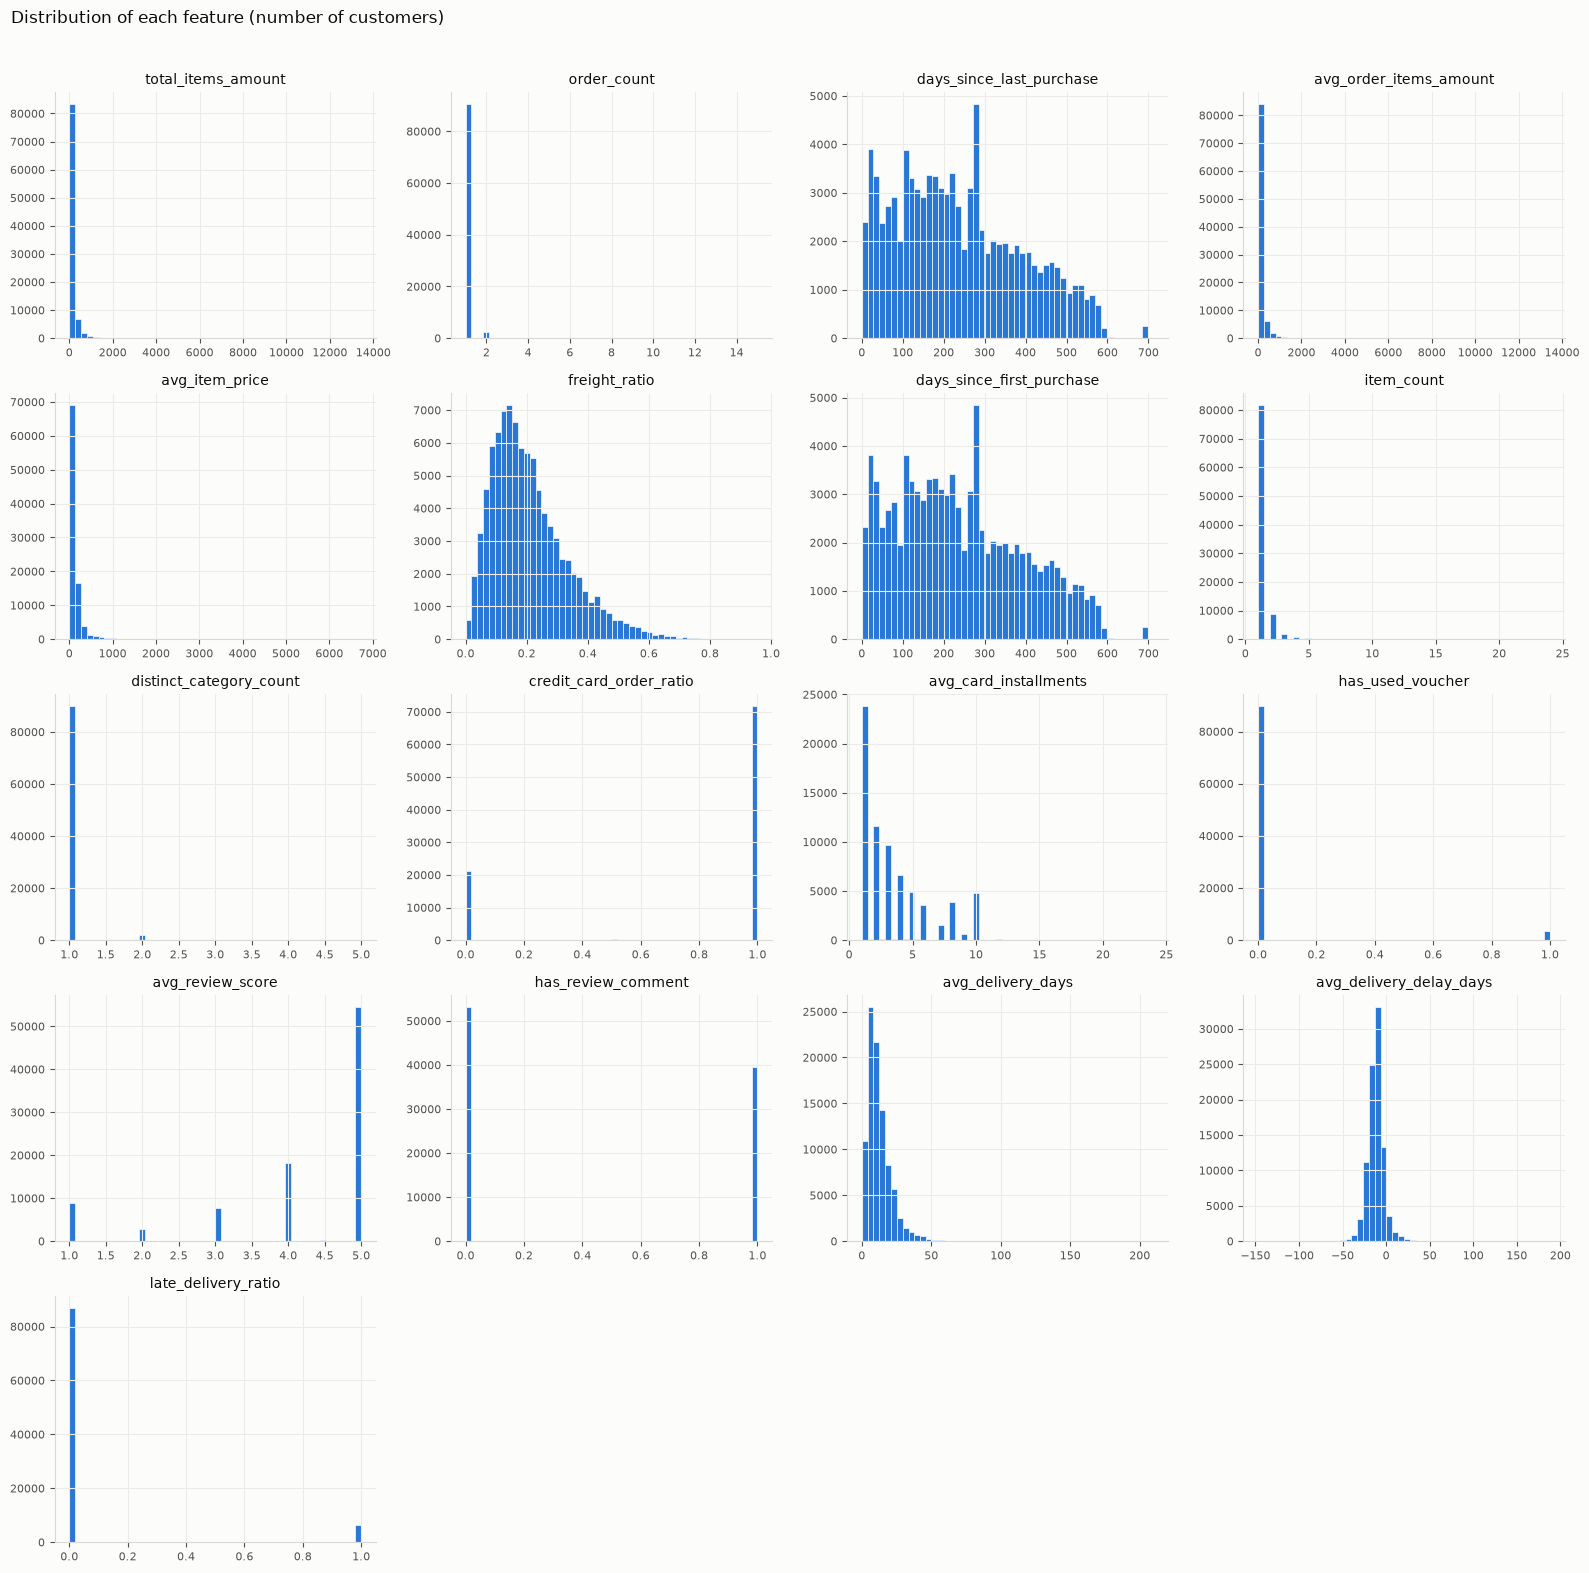

In [4]:
# グラフ内の文字は英語にする (日本語フォントがない環境でも同じように表示するため)
SURFACE = "#fcfcfb"
TEXT_PRIMARY = "#0b0b0b"
TEXT_SECONDARY = "#52514e"
SERIES = "#2a78d6"  # 単一系列のため 1 色のみ

plt.rcParams.update({
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "axes.edgecolor": "#d9d8d4",
    "axes.labelcolor": TEXT_SECONDARY,
    "axes.titlecolor": TEXT_PRIMARY,
    "xtick.color": TEXT_SECONDARY,
    "ytick.color": TEXT_SECONDARY,
    "axes.grid": True,
    "grid.color": "#ecebe8",
    "axes.spines.top": False,
    "axes.spines.right": False,
})


def plot_histograms(data: pd.DataFrame, columns: list[str], title: str, log: bool = False) -> None:
    """特徴量ごとのヒストグラムを並べて描く (NULL は除く)。"""
    n_cols = 4
    n_rows = int(np.ceil(len(columns) / n_cols))
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(16, 3.2 * n_rows))
    for ax, col in zip(axes.flat, columns):
        values = data[col].dropna()
        if log:
            values = np.log1p(values)
        ax.hist(values, bins=50, color=SERIES, edgecolor=SURFACE, linewidth=0.5)
        ax.set_title(f"log1p({col})" if log else col, fontsize=10)
        ax.tick_params(labelsize=8)
    for ax in list(axes.flat)[len(columns):]:
        ax.set_visible(False)
    fig.suptitle(title, x=0.01, ha="left", color=TEXT_PRIMARY)
    # 全体のタイトルが個々のグラフのタイトルと重ならないよう、上に余白を空ける
    fig.tight_layout(rect=(0, 0, 1, 0.97))
    plt.show()


plot_histograms(X, list(CANDIDATES), "Distribution of each feature (number of customers)")

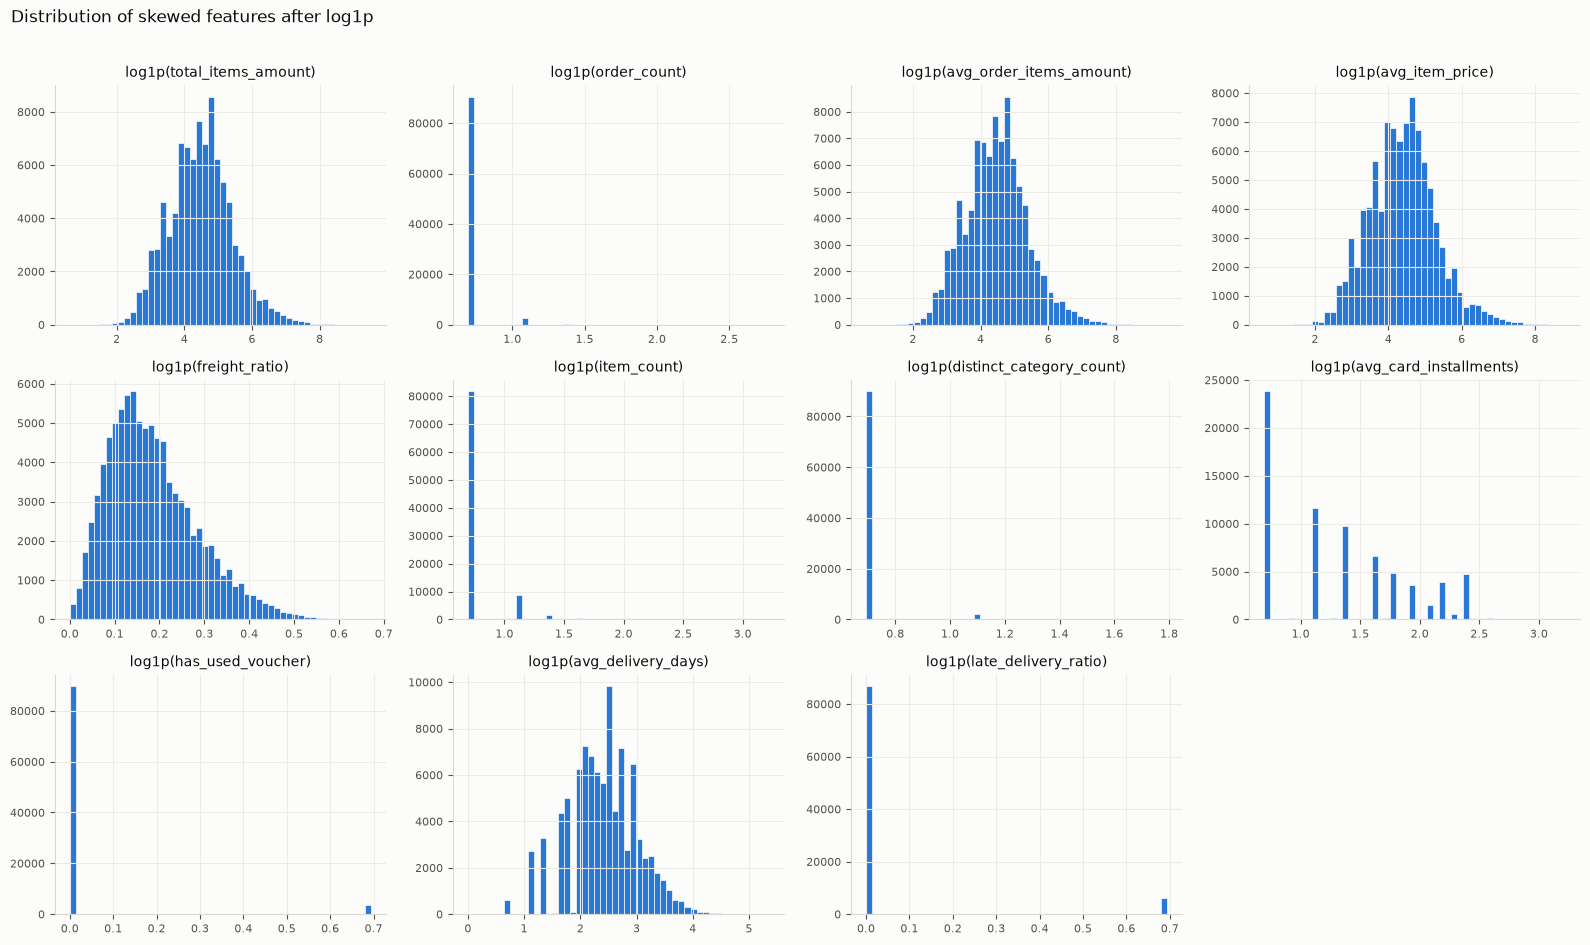

['total_items_amount',
 'order_count',
 'avg_order_items_amount',
 'avg_item_price',
 'freight_ratio',
 'item_count',
 'distinct_category_count',
 'avg_card_installments',
 'has_used_voucher',
 'avg_delivery_days',
 'late_delivery_ratio']

In [5]:
# 歪度が大きい (1 を超える) 非負の特徴量は、対数を取った分布も見る
skewed = [c for c in CANDIDATES if profile.loc[c, "skew"] > 1 and X[c].min() >= 0]
plot_histograms(X, skewed, "Distribution of skewed features after log1p", log=True)
skewed

## 3. 特徴量どうしの関係

偏りが大きく外れ値もあるため、順位相関 (スピアマン) で見る。NULL のある組は、両方に値がある顧客だけで計算する。

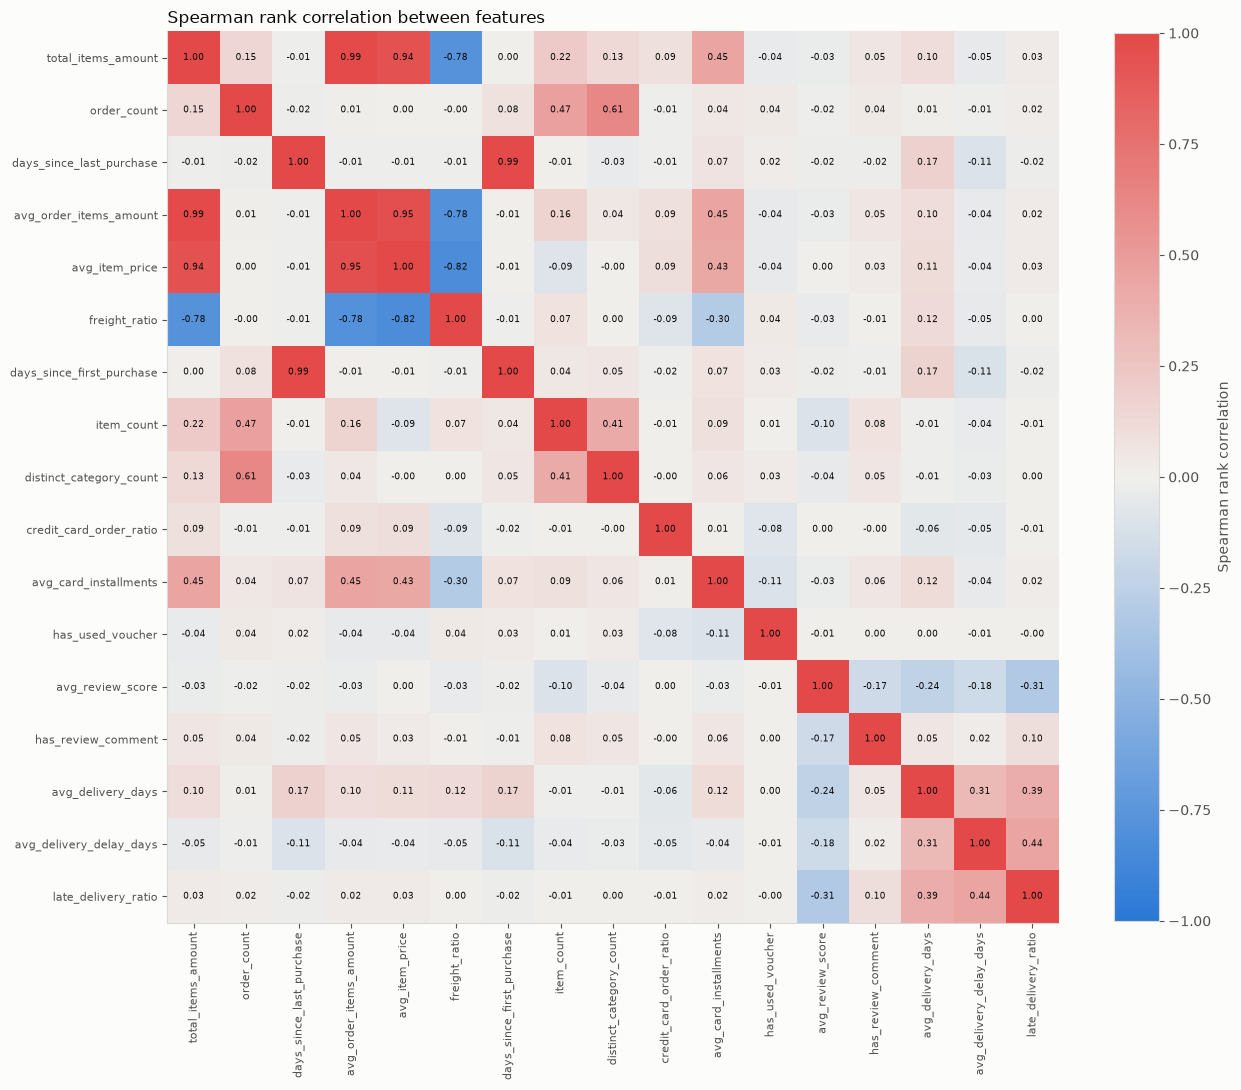

In [6]:
corr = X.corr(method="spearman")

# 青 (負) ↔ グレー (0) ↔ 赤 (正) の発散型の配色
DIVERGING = LinearSegmentedColormap.from_list("diverging", ["#2a78d6", "#f0efec", "#e34948"])

fig, ax = plt.subplots(figsize=(13, 11))
im = ax.imshow(corr, cmap=DIVERGING, vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=90, fontsize=8)
ax.set_yticks(range(len(corr)), corr.index, fontsize=8)
ax.grid(False)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=6.5, color=TEXT_PRIMARY)
fig.colorbar(im, ax=ax, fraction=0.04, label="Spearman rank correlation")
ax.set_title("Spearman rank correlation between features", loc="left")
fig.tight_layout()
plt.show()

In [7]:
# 相関の絶対値が 0.7 以上の組
pairs = (
    corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1))
    .stack()
    .rename("spearman")
    .reset_index()
    .rename(columns={"level_0": "feature_a", "level_1": "feature_b"})
)
pairs[pairs["spearman"].abs() >= 0.7].sort_values("spearman", key=abs, ascending=False)

,feature_a,feature_b,spearman
3,total_items_amount,avg_order_items_amount,0.989446
40,days_since_last_purchase,days_since_first_purchase,0.986780
55,avg_order_items_amount,avg_item_price,0.954540
4,total_items_amount,avg_item_price,0.943103
73,avg_item_price,freight_ratio,-0.821508
56,avg_order_items_amount,freight_ratio,-0.784209
5,total_items_amount,freight_ratio,-0.775488


## 4. 比較候補: `avg_delivery_delay_days` と `late_delivery_ratio`

同じ配送の実績を違う方法で要約した 2 つの候補を、合意した観点で比べる。

In [8]:
delivery = ["avg_delivery_delay_days", "late_delivery_ratio"]
pd.DataFrame({
    "null_rate": X[delivery].isna().mean(),
    "n_unique": X[delivery].nunique(),
    "top_value_share": X[delivery].apply(lambda s: s.value_counts(normalize=True).iloc[0]),
    "spearman_with_review": [X[[c, "avg_review_score"]].corr(method="spearman").iloc[0, 1] for c in delivery],
    "spearman_with_delivery_days": [X[[c, "avg_delivery_days"]].corr(method="spearman").iloc[0, 1] for c in delivery],
}).round(3)

,null_rate,n_unique,top_value_share,spearman_with_review,spearman_with_delivery_days
avg_delivery_delay_days,0.0,347,0.072,-0.178,0.313
late_delivery_ratio,0.0,12,0.930,-0.313,0.392


In [9]:
# 遅れの有無ごとの、レビューのスコアの平均 (配送の体験がスコアとどう関係するか)
late_group = np.select(
    [X["late_delivery_ratio"] == 0, X["late_delivery_ratio"] == 1],
    ["遅れなし", "すべて遅れ"],
    default="一部遅れ",
)
X.assign(late_group=late_group)[X["late_delivery_ratio"].notna()].groupby("late_group")["avg_review_score"].agg(["count", "mean"]).round(2)

,count,mean
late_group,,
すべて遅れ,6082,2.26
一部遅れ,271,3.23
遅れなし,86393,4.29


## 5. レビューの欠損と意味

`has_review_comment` は、レビューがない顧客を NULL、評価だけでコメントがない顧客を FALSE にしている (仕様書)。
レビューがない顧客 (`avg_review_score` が NULL) が、ほかの顧客とどう違うかを確認する。

In [10]:
review_status = np.select(
    [
        features["avg_review_score"].isna().to_numpy(),
        # NULL を含む真偽値のため、NULL を FALSE とみなして条件にする (NULL の顧客は 1 つ目の条件で先に判定される)
        features["has_review_comment"].fillna(False).to_numpy(dtype=bool),
    ],
    ["レビューなし", "コメントあり"],
    default="評価のみ (コメントなし)",
)
features.assign(review_status=review_status).groupby("review_status").agg(
    customers=("customer_unique_id", "count"),
    median_days_since_last_purchase=("days_since_last_purchase", "median"),
    share_last_7_days=("days_since_last_purchase", lambda s: (s <= 7).mean()),
    median_items_amount=("total_items_amount", "median"),
    late_delivery_ratio=("late_delivery_ratio", "mean"),
    avg_delivery_days=("avg_delivery_days", "mean"),
).round(3)

,customers,median_days_since_last_purchase,share_last_7_days,median_items_amount,late_delivery_ratio,avg_delivery_days
review_status,,,,,,
コメントあり,39609,212.0,0.007,92.50,0.095,13.301
レビューなし,604,248.5,0.002,98.95,0.238,18.666
評価のみ (コメントなし),53145,222.0,0.007,84.99,0.046,11.844


In [11]:
# 最終購入からの日数ごとの、レビューがない顧客の割合 (データの最後のほうに偏っているか)
bins = [-1, 7, 14, 30, 90, 180, 365, 1000]
labels = ["0-7", "8-14", "15-30", "31-90", "91-180", "181-365", "366+"]
(
    features.assign(
        days_bin=pd.cut(features["days_since_last_purchase"], bins=bins, labels=labels),
        no_review=features["avg_review_score"].isna(),
    )
    .groupby("days_bin", observed=True)["no_review"]
    .agg(customers="count", no_review_rate="mean")
    .round(3)
)

,customers,no_review_rate
days_bin,,
0-7,679,0.001
8-14,1725,0.006
15-30,4489,0.003
31-90,11627,0.005
91-180,19706,0.006
181-365,34452,0.007
366+,20680,0.007


## 考察

### NULL の割合
- NULL が多いのは `avg_card_installments` (22.9%) だけ。ほかは 1.3% 以下。

### ほとんどの顧客が同じ値になる特徴量
- `distinct_category_count` (97.7% が 1)、`order_count` (97.0% が 1)、`has_used_voucher` (96.2% が FALSE)、`late_delivery_ratio` (93.0% が 0)、`item_count` (87.6% が 1)。
- 顧客の約 97% が 1 回購入であるというデータの構造が、多くの特徴量に影響している。

### 偏り
- 金額の特徴量は偏りが大きい (歪度 8〜10。中央値約 90 レアルに対して最大 13,440 レアル)。対数変換が必要。

### 似た情報を持つ組 (順位相関の絶対値 0.7 以上)
- `total_items_amount`・`avg_order_items_amount`・`avg_item_price` (0.94〜0.99): 1 回購入・1 商品の顧客が多く、ほぼ同じ値になる。
- `days_since_last_purchase`・`days_since_first_purchase` (0.99): 1 回購入の顧客では同じ値になる。
- `freight_ratio` と金額の特徴量 (−0.78〜−0.82): 送料は価格に比例しないため、安い商品ほど送料の割合が高くなる。

### 配送の比較候補
- `late_delivery_ratio` のほうが、レビューのスコアとの関係が強い (順位相関 −0.31。`avg_delivery_delay_days` は −0.18)。
- 遅れを経験した顧客のレビューの平均は、すべて遅れ 2.26 / 一部遅れ 3.23 / 遅れなし 4.29。
- 「遅れを経験した顧客」と解釈しやすい `late_delivery_ratio` を採用する。

### レビューの欠損
- レビューがない顧客 (604 人、約 0.65%) は、ほかの顧客と比べて、遅れを経験した割合が高く (23.8%。コメントあり 9.5%、評価のみ 4.6%)、配送日数の平均も長い (18.7 日。同 13.3 日、11.8 日)。
- 最終購入からの日数による偏りはない (データの最後のほうに購入した顧客に偏っているわけではない)。
- レビューの欠損と配送の体験には関連がある可能性があるが、因果関係は判断できない。
- 欠損がランダムではない可能性があるため、平均値などで単純に補完しない。補完の方法はセグメンテーションの段階で、この関連を踏まえて決める。
- コメントありの顧客は、評価のみの顧客より遅れを経験した割合が高い (9.5% と 4.6%)。コメントの有無と配送の体験にも関連がある可能性がある。

### 選定の結果

採用 (8 つ): `total_items_amount` (対数変換)、`order_count`、`days_since_last_purchase`、`item_count`、`credit_card_order_ratio`、`avg_review_score`、`has_review_comment`、`late_delivery_ratio`

保留: `avg_card_installments`

判断の理由と、次の段階で確認することは `docs/decisions/008_feature_selection.md` にまとめる。